In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

In [4]:
# Open the first data file
d1 = pd.read_csv('loan_data.csv')

In [5]:
d1.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


# Fix Missing Values

In [7]:
d1.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [8]:
d1.dtypes

Loan_ID               object
Gender                object
Married               object
Dependents            object
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object

### Gender

<Axes: >

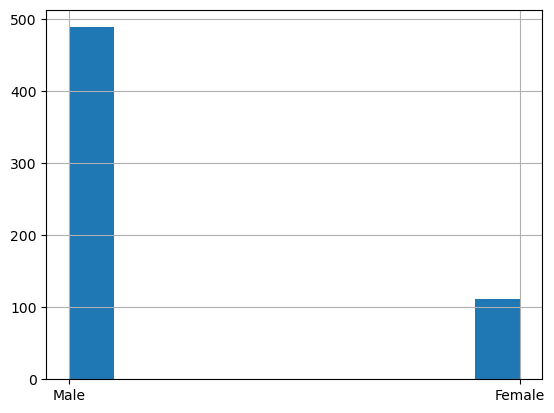

In [10]:
d1["Gender"].hist()

In [11]:
d1.groupby(["Gender"]).agg({'Gender':'count'})

,Gender
Gender,
Female,112
Male,489


In [12]:
d1["Gender"].fillna("Male", inplace=True)

/var/folders/dd/pf2ksl1n2rv7sv124lh3xz0m0000gn/T/ipykernel_81005/2764681623.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d1["Gender"].fillna("Male", inplace=True)


## Married

<Axes: >

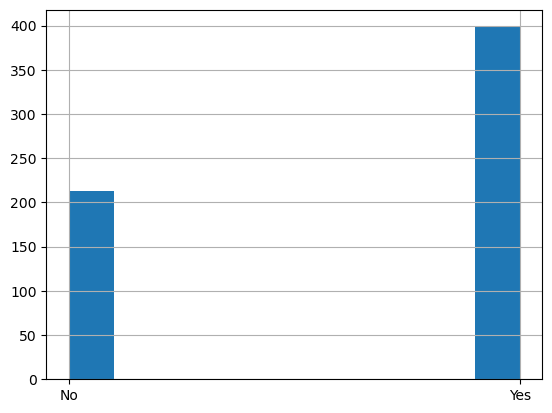

In [14]:
d1["Married"].hist()

In [15]:
d1.groupby(["Married"]).agg({'Married':'count'})

,Married
Married,
No,213
Yes,398


In [16]:
d1["Married"].fillna("Yes", inplace=True)

/var/folders/dd/pf2ksl1n2rv7sv124lh3xz0m0000gn/T/ipykernel_81005/2799416157.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d1["Married"].fillna("Yes", inplace=True)


## Dependents

<Axes: >

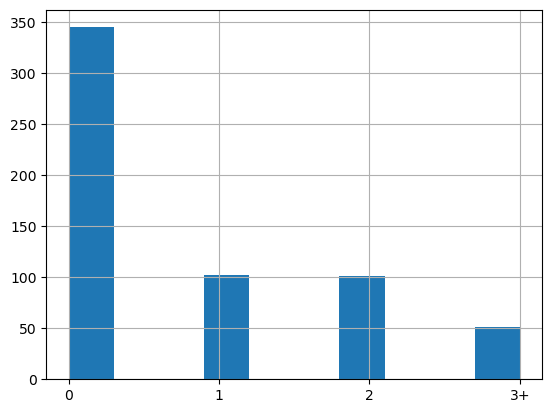

In [18]:
d1["Dependents"].hist()

In [19]:
d1.groupby(["Dependents"]).agg({'Dependents':'count'})

,Dependents
Dependents,
0,345
1,102
2,101
3+,51


In [20]:
d1["Dependents"].fillna("0", inplace=True)

/var/folders/dd/pf2ksl1n2rv7sv124lh3xz0m0000gn/T/ipykernel_81005/1354278007.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d1["Dependents"].fillna("0", inplace=True)


## Self_Employed

<Axes: >

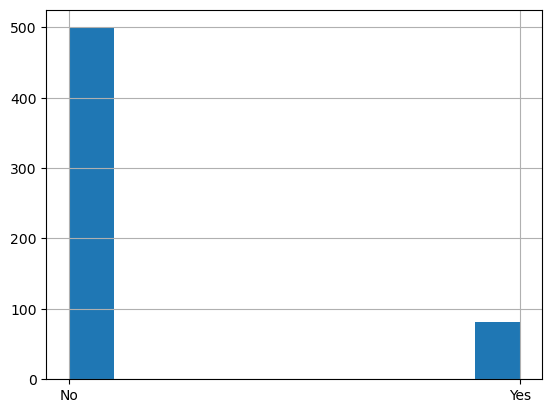

In [22]:
d1["Self_Employed"].hist()

In [23]:
d1.groupby(["Self_Employed"]).agg({'Self_Employed':'count'})

,Self_Employed
Self_Employed,
No,500
Yes,82


In [24]:
d1["Self_Employed"].fillna("No", inplace=True)

/var/folders/dd/pf2ksl1n2rv7sv124lh3xz0m0000gn/T/ipykernel_81005/205949479.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d1["Self_Employed"].fillna("No", inplace=True)


## LoanAmount

<Axes: >

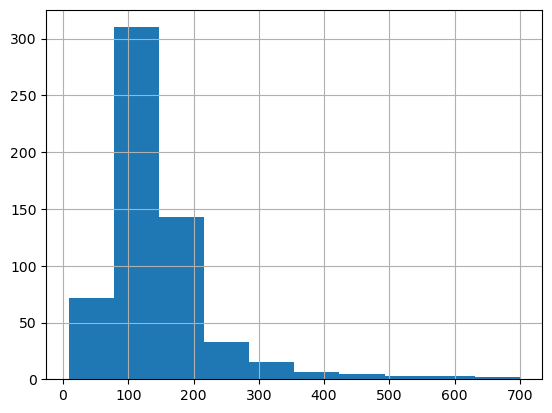

In [26]:
d1["LoanAmount"].hist()

In [27]:
d1['LoanAmount'].mean()

146.41216216216216

In [28]:
d1["LoanAmount"].fillna(d1["LoanAmount"].mean(), inplace=True)

/var/folders/dd/pf2ksl1n2rv7sv124lh3xz0m0000gn/T/ipykernel_81005/1885972458.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d1["LoanAmount"].fillna(d1["LoanAmount"].mean(), inplace=True)


## Loan_Amount_Term

<Axes: >

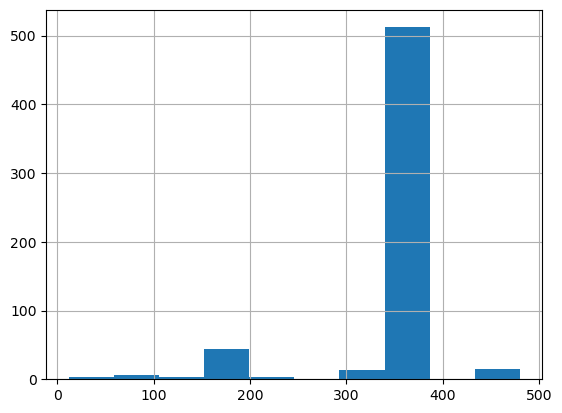

In [30]:
d1["Loan_Amount_Term"].hist()

In [31]:
d1['Loan_Amount_Term'].mean()

342.0

In [32]:
d1["Loan_Amount_Term"].fillna(d1["Loan_Amount_Term"].mean(), inplace=True)

/var/folders/dd/pf2ksl1n2rv7sv124lh3xz0m0000gn/T/ipykernel_81005/2641654770.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d1["Loan_Amount_Term"].fillna(d1["Loan_Amount_Term"].mean(), inplace=True)


## Credit_History

<Axes: >

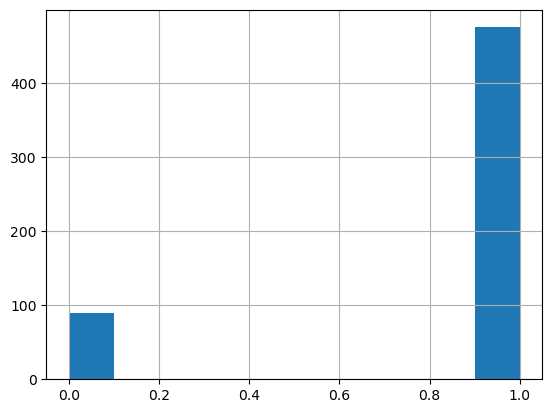

In [34]:
d1["Credit_History"].hist()

In [35]:
d1['Credit_History'].mean()

0.8421985815602837

In [36]:
d1["Credit_History"].fillna(d1["Credit_History"].mean(), inplace=True)

/var/folders/dd/pf2ksl1n2rv7sv124lh3xz0m0000gn/T/ipykernel_81005/2574505050.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  d1["Credit_History"].fillna(d1["Credit_History"].mean(), inplace=True)


In [37]:
d1.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

For all object variables, I used the most frequent value. For instance, male was more frequent than female in the gender column so I switched all missing values to male.

For the float varaibles, I used the mean number to fill in the missing values. For instance, I took the average loan amount and assigned it to all missing variables in the LoanAmount column.

# Checking for Outliers

In [40]:
d1.dtypes

Loan_ID               object
Gender                object
Married               object
Dependents            object
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object

#### ApplicantIncome

<Axes: >

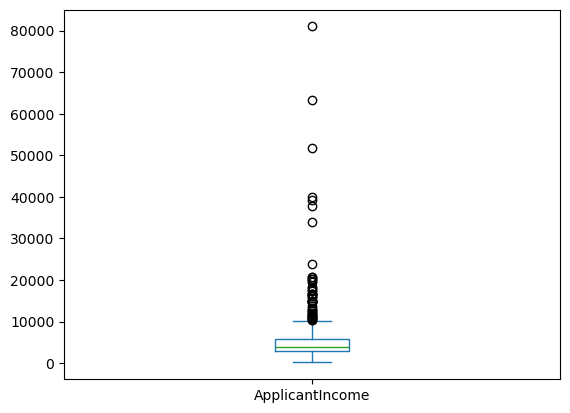

In [42]:
d1['ApplicantIncome'].plot.box()

In [43]:
d1.sort_values('ApplicantIncome', ascending=False).head(13)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
409,LP002317,Male,Yes,3+,Graduate,No,81000,0.0,360.000000,360.0,0.000000,Rural,N
333,LP002101,Male,Yes,0,Graduate,No,63337,0.0,490.000000,180.0,1.000000,Urban,Y
171,LP001585,Male,Yes,3+,Graduate,No,51763,0.0,700.000000,300.0,1.000000,Urban,Y
155,LP001536,Male,Yes,3+,Graduate,No,39999,0.0,600.000000,180.0,0.000000,Semiurban,Y
185,LP001640,Male,Yes,0,Graduate,Yes,39147,4750.0,120.000000,360.0,1.000000,Semiurban,Y
443,LP002422,Male,No,1,Graduate,No,37719,0.0,152.000000,360.0,1.000000,Semiurban,Y
183,LP001637,Male,Yes,1,Graduate,No,33846,0.0,260.000000,360.0,1.000000,Semiurban,N
126,LP001448,Male,Yes,3+,Graduate,No,23803,0.0,370.000000,360.0,1.000000,Rural,Y
506,LP002624,Male,Yes,0,Graduate,No,20833,6667.0,480.000000,360.0,0.842199,Urban,Y
284,LP001922,Male,Yes,0,Graduate,No,20667,0.0,146.412162,360.0,1.000000,Rural,N


I will remove all outliers greater than 20000 (inclusive) applicant income because those are more extreme outliers than those between 10000-20000. This will give a more accurate representation of those looking to get loans.

In [45]:
d1.drop([409,333,171,155,185,443,183,126,506,284,308,130], inplace=True)

<Axes: >

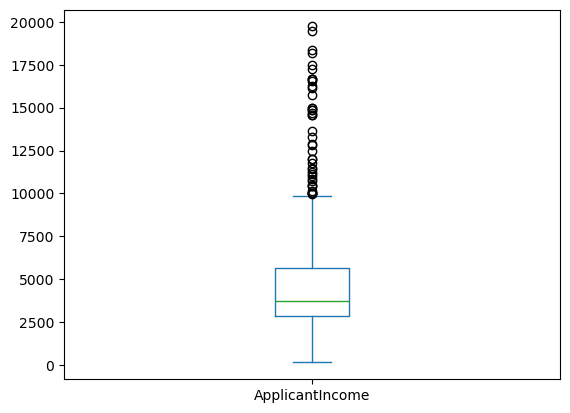

In [46]:
d1['ApplicantIncome'].plot.box()

#### CoapplicantIncome

<Axes: >

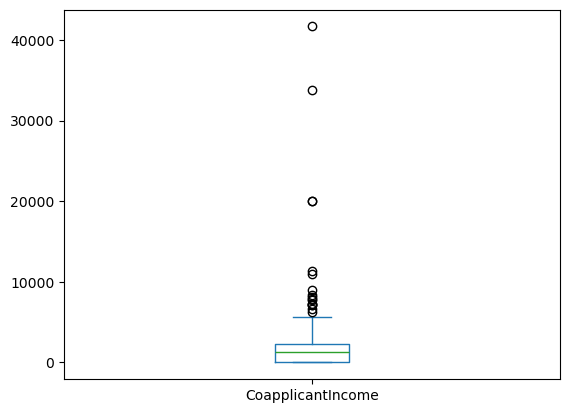

In [48]:
d1['CoapplicantIncome'].plot.box()

I will do the same as I did for applicant income to make a more accurate model.

In [50]:
d1.sort_values('CoapplicantIncome', ascending=False).head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
600,LP002949,Female,No,3+,Graduate,No,416,41667.0,350.0,180.0,0.842199,Urban,N
581,LP002893,Male,No,0,Graduate,No,1836,33837.0,90.0,360.0,1.000000,Urban,N
402,LP002297,Male,No,0,Graduate,No,2500,20000.0,103.0,360.0,1.000000,Semiurban,Y
417,LP002342,Male,Yes,2,Graduate,Yes,1600,20000.0,239.0,360.0,1.000000,Urban,N
177,LP001610,Male,Yes,3+,Graduate,No,5516,11300.0,495.0,360.0,0.000000,Semiurban,N


In [51]:
d1.drop([600,581,402,417], inplace=True)

<Axes: >

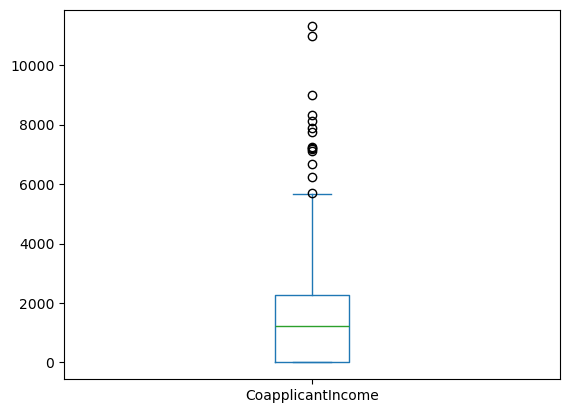

In [52]:
d1['CoapplicantIncome'].plot.box()

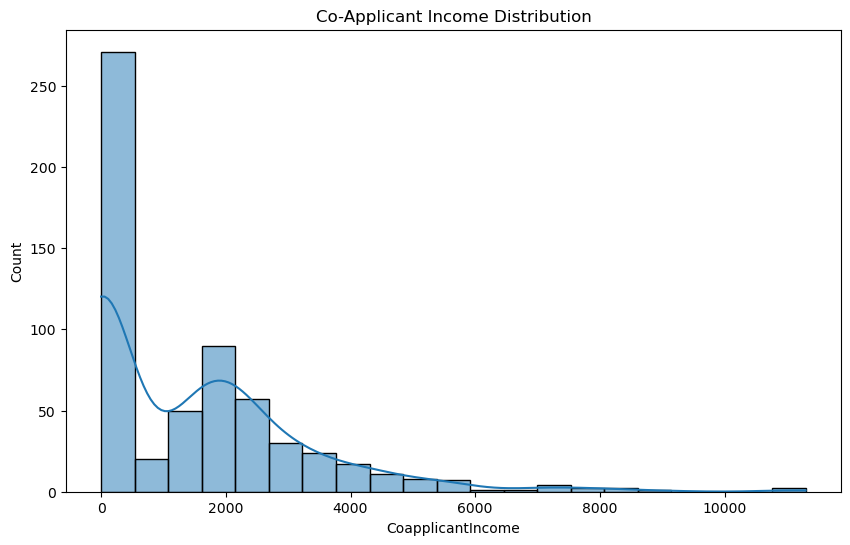

In [53]:
plt.figure(figsize=(10, 6))
sns.histplot(d1['CoapplicantIncome'], kde=True)
plt.title('Co-Applicant Income Distribution')
plt.show()

#### LoanAmount

<Axes: >

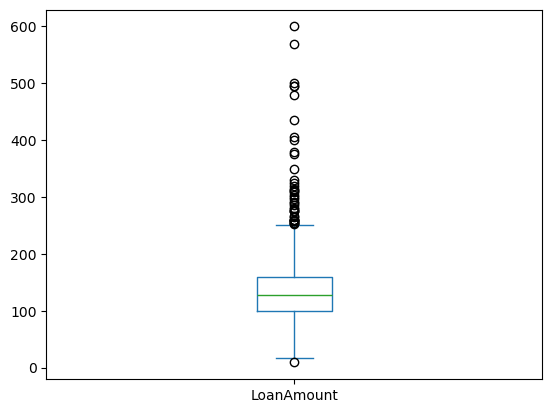

In [55]:
d1['LoanAmount'].plot.box()

In [56]:
d1.sort_values('LoanAmount', ascending=True).head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
568,LP002840,Female,No,0,Graduate,No,2378,0.0,9.0,360.0,1.0,Urban,N
14,LP001030,Male,Yes,2,Graduate,No,1299,1086.0,17.0,120.0,1.0,Urban,Y
94,LP001325,Male,No,0,Not Graduate,No,3620,0.0,25.0,120.0,1.0,Semiurban,Y
133,LP001482,Male,Yes,0,Graduate,Yes,3459,0.0,25.0,120.0,1.0,Semiurban,Y
555,LP002792,Male,Yes,1,Graduate,No,5468,1032.0,26.0,360.0,1.0,Semiurban,Y


In [57]:
d1.sort_values('LoanAmount', ascending=False).head(20)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
561,LP002813,Female,Yes,1,Graduate,Yes,19484,0.0,600.0,360.0,1.000000,Semiurban,Y
369,LP002191,Male,Yes,0,Graduate,No,19730,5266.0,570.0,360.0,1.000000,Rural,N
487,LP002547,Male,Yes,1,Graduate,No,18333,0.0,500.0,360.0,1.000000,Urban,N
604,LP002959,Female,Yes,1,Graduate,No,12000,0.0,496.0,360.0,1.000000,Semiurban,Y
177,LP001610,Male,Yes,3+,Graduate,No,5516,11300.0,495.0,360.0,0.000000,Semiurban,N
523,LP002693,Male,Yes,2,Graduate,Yes,7948,7166.0,480.0,360.0,1.000000,Rural,Y
278,LP001907,Male,Yes,0,Graduate,No,14583,0.0,436.0,360.0,1.000000,Semiurban,Y
432,LP002386,Male,No,0,Graduate,No,12876,0.0,405.0,360.0,1.000000,Semiurban,Y
525,LP002699,Male,Yes,2,Graduate,Yes,17500,0.0,400.0,360.0,1.000000,Rural,Y
372,LP002201,Male,Yes,2,Graduate,Yes,9323,7873.0,380.0,300.0,1.000000,Rural,Y


I will drop outliers greater than 400 (inclusive) so it will be less skewed. I do not want to drop all of them because there are more than ten points in the range of 350-400. I will also drop the singular lower outlier. 

In [59]:
d1.drop([568, 561,369,487,604,177,523,278,432,525], inplace=True)

<Axes: >

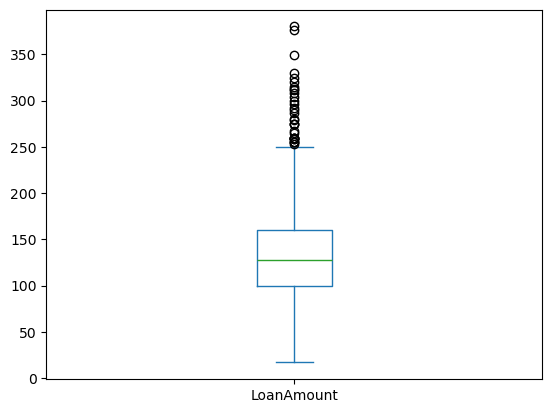

In [60]:
d1['LoanAmount'].plot.box()

plt.figure(figsize=(10, 6))
sns.histplot(d1['LoanAmount'], kde=True)
plt.title('Loan Amount Distribution')
plt.show()

#### Loan_Amount_Term

<Axes: >

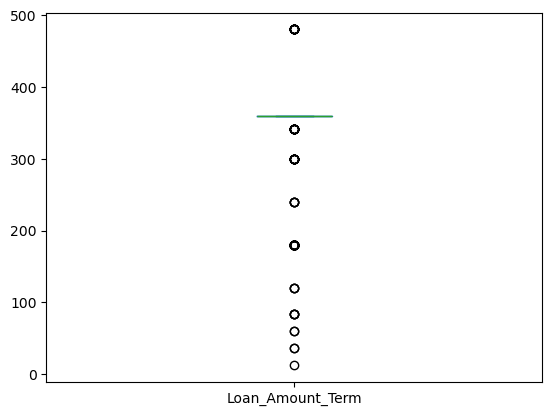

In [63]:
d1['Loan_Amount_Term'].plot.box()

In [64]:
d1.sort_values('Loan_Amount_Term', ascending=False).head(20)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
248,LP001824,Male,Yes,1,Graduate,No,2882,1843.0,123.0,480.0,1.000000,Semiurban,Y
516,LP002670,Female,Yes,2,Graduate,No,2031,1632.0,113.0,480.0,1.000000,Semiurban,Y
109,LP001384,Male,Yes,3+,Not Graduate,No,2071,754.0,94.0,480.0,1.000000,Semiurban,Y
573,LP002862,Male,Yes,2,Not Graduate,No,6125,1625.0,187.0,480.0,1.000000,Semiurban,N
168,LP001579,Male,No,0,Graduate,No,2237,0.0,63.0,480.0,0.000000,Semiurban,N
500,LP002603,Female,No,0,Graduate,No,645,3683.0,113.0,480.0,1.000000,Rural,Y
378,LP002224,Male,No,0,Graduate,No,3069,0.0,71.0,480.0,1.000000,Urban,N
298,LP001955,Female,No,0,Graduate,No,5000,2541.0,151.0,480.0,1.000000,Rural,N
228,LP001760,Male,Yes,0,Graduate,No,4758,0.0,158.0,480.0,1.000000,Semiurban,Y
179,LP001630,Male,No,0,Not Graduate,No,2333,1451.0,102.0,480.0,0.000000,Urban,N


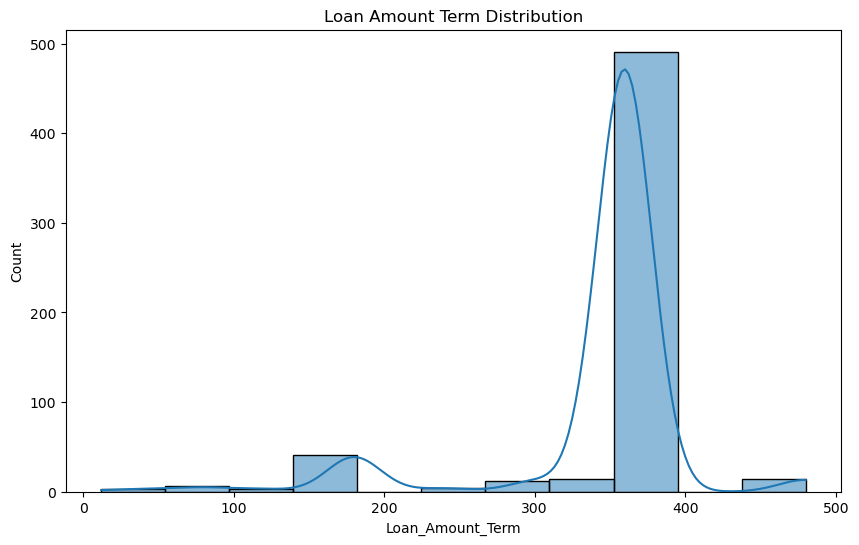

In [65]:
plt.figure(figsize=(10, 6))
sns.histplot(d1['Loan_Amount_Term'], kde=True)
plt.title('Loan Amount Term Distribution')
plt.show()

I will not be removing any outliers because there are too many outliers. This would minimize the dataset extremely. Instead it would be better scale and transform it because it is so spread out.

#### Credit_History

<Axes: >

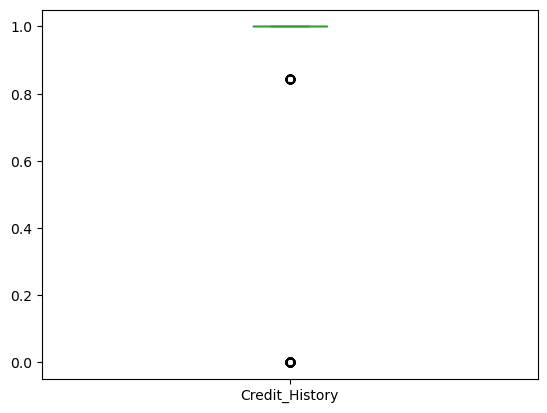

In [68]:
d1['Credit_History'].plot.box()

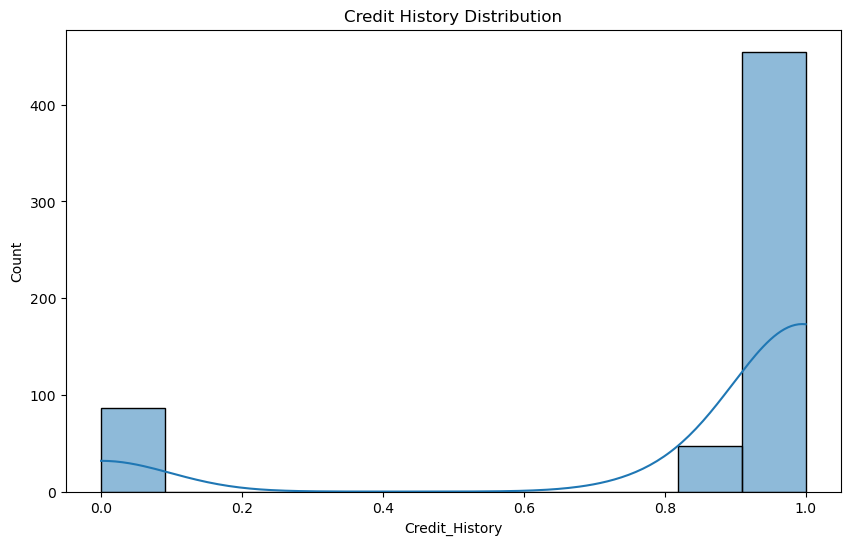

In [69]:
plt.figure(figsize=(10, 6))
sns.histplot(d1['Credit_History'], kde=True)
plt.title('Credit History Distribution')
plt.show()

same situation here. I will not remove outliers but will need to scale and transform. 

## Descretize
All of my ranges will be based on the quartiles (Q1,Q2,Q3,Q4). 

### ApplicantIncome

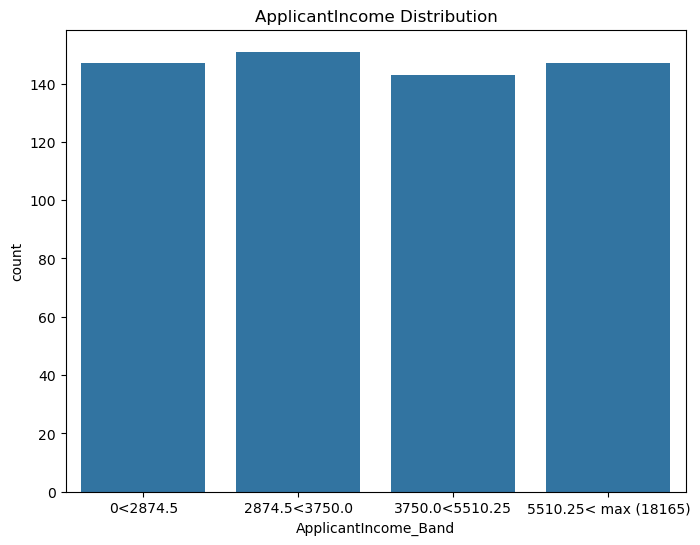

In [73]:
Q1 = d1['ApplicantIncome'].quantile(0.25) 
string1 = "0<"+str(Q1)
Q2 = d1['ApplicantIncome'].quantile(0.50) 
string2 = str(Q1)+"<"+str(Q2)
Q3 = d1['ApplicantIncome'].quantile(0.75)
string3 = str(Q2)+"<"+str(Q3)
Q4 = d1['ApplicantIncome'].max()
string4 = str(Q3)+"< max ("+str(Q4)+")"
d1['ApplicantIncome_Band'] = pd.qcut(d1['ApplicantIncome'], q=4, labels=[string1, string2, string3, string4])

# Plotting
plt.figure(figsize=(8, 6))
sns.countplot(x=d1['ApplicantIncome_Band'])
plt.title('ApplicantIncome Distribution')
plt.show()

### CoapplicantIncome

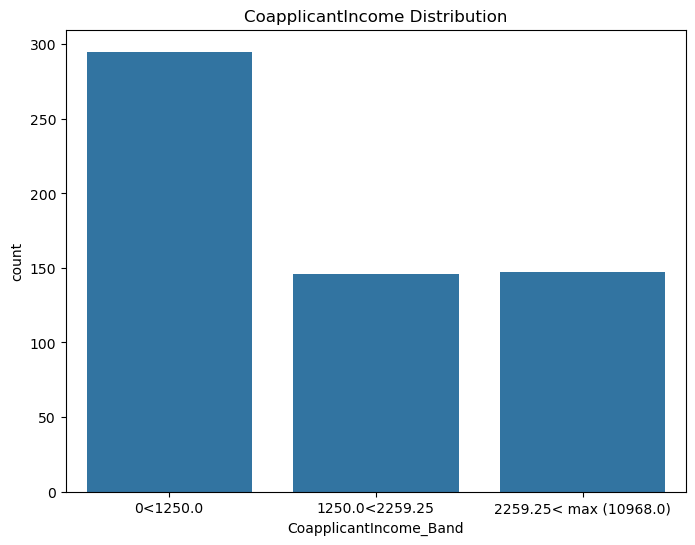

In [75]:
##the co-applicant income does not have a first quartile so I will not have a bar for it here.
Q2 = d1['CoapplicantIncome'].quantile(0.50) 
string2 = "0<"+str(Q2)
Q3 = d1['CoapplicantIncome'].quantile(0.75)
string3 = str(Q2)+"<"+str(Q3)
Q4 = d1['CoapplicantIncome'].max()
string4 = str(Q3)+"< max ("+str(Q4)+")"
d1['CoapplicantIncome_Band'] = pd.qcut(d1['CoapplicantIncome'], q=4, labels=[string2, string3, string4], duplicates='drop')

# Plotting
plt.figure(figsize=(8, 6))
sns.countplot(x=d1['CoapplicantIncome_Band'])
plt.title('CoapplicantIncome Distribution')
plt.show()

### LoanAmount

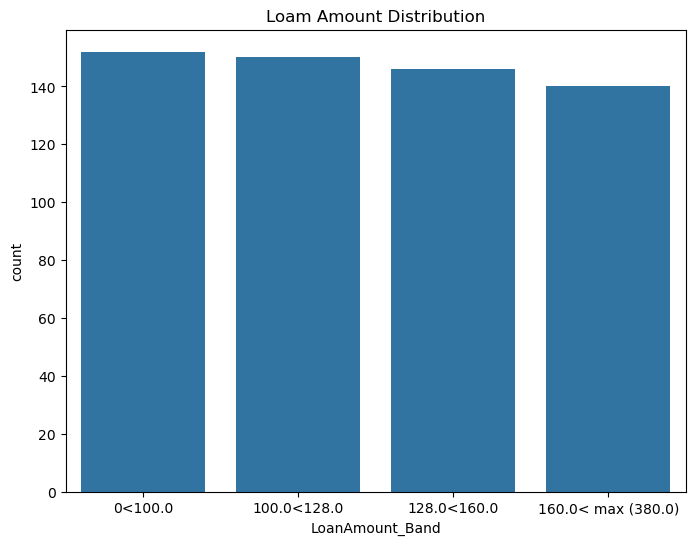

In [77]:
Q1 = d1['LoanAmount'].quantile(0.25) 
string1 = "0<"+str(Q1)
Q2 = d1['LoanAmount'].quantile(0.50) 
string2 = str(Q1)+"<"+str(Q2)
Q3 = d1['LoanAmount'].quantile(0.75)
string3 = str(Q2)+"<"+str(Q3)
Q4 = d1['LoanAmount'].max()
string4 = str(Q3)+"< max ("+str(Q4)+")"
d1['LoanAmount_Band'] = pd.qcut(d1['LoanAmount'], q=4, labels=[string1, string2, string3, string4])

# Plotting
plt.figure(figsize=(8, 6))
sns.countplot(x=d1['LoanAmount_Band'])
plt.title('Loam Amount Distribution')
plt.show()

### Loan_Amount_Term
For this column I will do discrete categories beacuse there is not a wide range looking at the boxplot. It is more specific data values which will be easier to classify as low medium or high.

<Axes: >

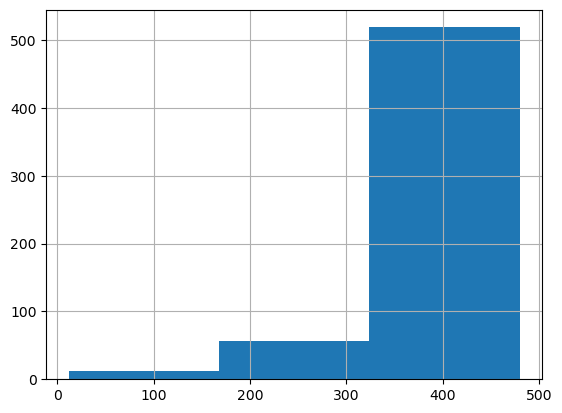

In [79]:
d1['Loan_Amount_Term'].hist(bins=3)

In [80]:
bin_edges = np.histogram(d1['Loan_Amount_Term'], bins=3)[1]
# Print the bin edges
print("Bin edges:", bin_edges)

Bin edges: [ 12. 168. 324. 480.]


This means that the ranges for my low medium high categories will be (12<168,168<324,324<480)

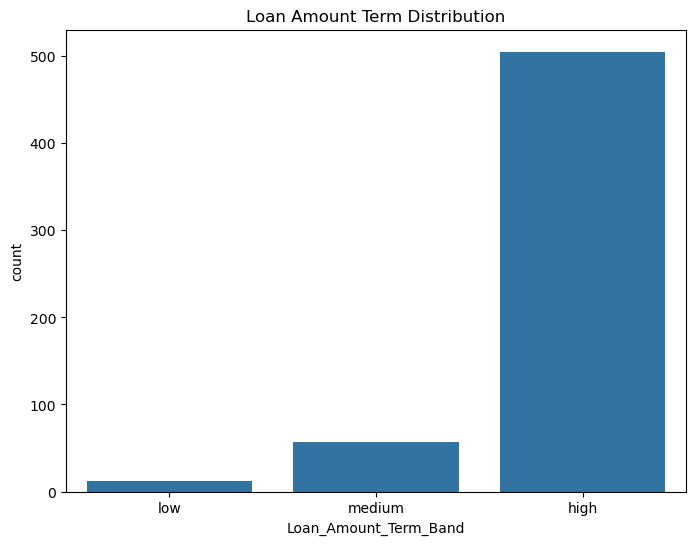

In [82]:
bins = [12, 168, 324, 480]
labels = ['low', 'medium', 'high']
d1['Loan_Amount_Term_Band'] = pd.cut(d1['Loan_Amount_Term'], bins=bins, labels=labels, right=False)

# Plotting the categorical bands
plt.figure(figsize=(8, 6))
sns.countplot(x=d1['Loan_Amount_Term_Band'])
plt.title('Loan Amount Term Distribution')
plt.show()

## My Predictors

In [84]:
d1.dtypes

Loan_ID                     object
Gender                      object
Married                     object
Dependents                  object
Education                   object
Self_Employed               object
ApplicantIncome              int64
CoapplicantIncome          float64
LoanAmount                 float64
Loan_Amount_Term           float64
Credit_History             float64
Property_Area               object
Loan_Status                 object
ApplicantIncome_Band      category
CoapplicantIncome_Band    category
LoanAmount_Band           category
Loan_Amount_Term_Band     category
dtype: object

I will be using (Education, applicant income, co-applicant income, loan amount, credit history, ). I find these to be some of the major reasons why loans can be accepted or not in the real world so I would like to see if there is a correlation. I excluded gender, married, and self-employed because, in the modern era, this should not matter as much as there are influencers and people not married.

# Scale, Transform, Encode Models
## Naive Bayes

In [87]:
# Columns that require transformation to reduce skew
columns_to_transform = [
    'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 
    'Loan_Amount_Term', 'Credit_History'
]

# Apply log transformation
for col in columns_to_transform:
    d1[f'{col}_log'] = np.log1p(d1[col])

# Columns to be scaled after transformation
columns_to_scale = [
   'ApplicantIncome_log', 'CoapplicantIncome_log', 'LoanAmount_log', 
    'Loan_Amount_Term_log', 'Credit_History_log'
]

# Scaling the transformed columns
scaler = StandardScaler()
d1[columns_to_scale] = scaler.fit_transform(d1[columns_to_scale])

categorical_columns = ['Education']
for col in categorical_columns:
    encoder = LabelEncoder()
    d1[col] = encoder.fit_transform(d1[col])
    # Define features (X) and target (y)
X = d1[columns_to_scale + categorical_columns]  # Using scaled, transformed, and encoded features
y = d1['Loan_Status']  # Target variable: credit_score

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

# AUC for multi-class classification using One-vs-Rest (OvR)
print("AUC:", roc_auc_score(y_test, y_pred_proba, multi_class='ovr'))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7796610169491526
AUC: 0.7251141552511414

Classification Report:
               precision    recall  f1-score   support

           N       0.95      0.44      0.61        45
           Y       0.74      0.99      0.85        73

    accuracy                           0.78       118
   macro avg       0.85      0.72      0.73       118
weighted avg       0.82      0.78      0.76       118



## kNN Classification

In [89]:
# Initialize the k-NN classifier (using k=5 as a starting point)
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the k-NN model
knn_model.fit(X_train, y_train)

# Predict on the test set
y_pred = knn_model.predict(X_test)
y_pred_proba = knn_model.predict_proba(X_test)[:,1]


# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, y_pred_proba))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7627118644067796
AUC: 0.7386605783866058

Classification Report:
               precision    recall  f1-score   support

           N       0.81      0.49      0.61        45
           Y       0.75      0.93      0.83        73

    accuracy                           0.76       118
   macro avg       0.78      0.71      0.72       118
weighted avg       0.77      0.76      0.75       118



## Logistic Regression Classification

In [91]:
# Initialize the Logistic Regression model
logreg_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the Logistic Regression model
logreg_model.fit(X_train, y_train)

# Predict on the test set
y_pred = logreg_model.predict(X_test)
y_pred_proba = logreg_model.predict_proba(X_test)[:, 1]


# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, y_pred_proba))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7796610169491526
AUC: 0.7327245053272451

Classification Report:
               precision    recall  f1-score   support

           N       0.95      0.44      0.61        45
           Y       0.74      0.99      0.85        73

    accuracy                           0.78       118
   macro avg       0.85      0.72      0.73       118
weighted avg       0.82      0.78      0.76       118



Naive does a good job with handling categorical variables as I have one but is very good with numerical assuming they are a normal distribution and easiest to work with. Based on the band, they are fairly distributed. Knn relies on the distance between values. This will help account for columns that have a lot of outliers that are close together. A logistic regression is good for handling both categorical and numerical like in this case, especially after scaling and encoding. 

All of the accuracies are relatively similar, rounded to 0.7. Looking more closely, Naive (0.77966), KNN (0.76271), and logistic (0.77966). 

Looking at the AUC Naive(0.72511), KNN (0.73866), and Logistic (0.73272), you want the higher one which is KNN. 

After changing some variables around I noticed that the choice of categorical variable could greatly improve the outcome of the logistic and Naive models but greatly hurt the KNN model's accuracy. I would recommend the Naive Bayes model because it has the best accuracy tied with the logistic regression model but looking at the AUC, Naive Bayes outperforms the Logistic model. I think if I rarely used numerical values, the KNN model would outperform but because I have a combination it is not doing as well. A lot of the noise that could probably made this more accurate would be to fully get rid of all outliers instead of getting rid of the most extreme outliers. If I had also chosen all numerical variables that had an even distribution instead of a mix, that would have helped the Naive Bayes model. This is an acceptable model because it is at least 70% accurate and its AUC is also within 70%. I would not say it's the most amazing because these numbers are still on the lower side. 